In [9]:
import pandas as pd   
import numpy as np    
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score

import seaborn as sns
import matplotlib.pyplot as plt


### 데이터 설명

| 변수명           | 데이터타입 | 설명                        | 범주 값 또는 예시                                                                                                                         |
| ------------- | ----- | ------------------------- | ---------------------------------------------------------------------------------------------------------------------------------- |
| **age**       | 수치형   | 나이                        | -                                                                                                                                  |
| **job**       | 범주형   | 직업                        | admin, unknown, unemployed, management, housemaid, entrepreneur, student, blue-collar, self-employed, retired, technician, service |
| **marital**   | 범주형   | 결혼상태                      | married, divorced,single (사별해도 divorced로 포함)                                                                                                          |
| **education** | 범주형   | 학력                        | unknown, secondary, primary, tertiary                                                                                              |
| **default**   | 범주형   | 신용 채무 불이행 여부              | yes, no                                                                                                                            |
| **balance**   | 수치형   | 연평균 잔액 (단위: 유로)           | -                                                                                                                                  |
| **housing**   | 범주형   | 주택 대출 여부                  | yes, no                                                                                                                            |
| **loan**      | 범주형   | 개인 대출 여부                  | yes, no                                                                                                                            |
| **contact**   | 범주형   | 최근 연락 수단                  | unknown, telephone, cellular                                                                                                       |
| **day**       | 수치형   | 최근 연락 날짜                  | 1 \~ 31                                                                                                                            |
| **month**     | 범주형   | 최근 연락한 달                  | jan, feb, mar, ..., dec                                                                                                            |
| **duration**  | 수치형   | 최근 통화 시간 (초)              | -                                                                                                                                  |
| **campaign**  | 수치형   | 이번 캠페인 중 고객에게 연락한 횟수      | -                                                                                                                                  |
| **pdays**     | 수치형   | 이전 캠페인 이후 경과일 (-1은 연락 없음) | -                                                                                                                                  |
| **previous**  | 수치형   | 이전 캠페인에서 고객에게 연락한 횟수      | -                                                                                                                                  |
| **poutcome**  | 범주형   | 이전 캠페인 결과                 | unknown, other, failure, success                                                                                                   |
| **label**     | 범주형   | 정기예금 가입 여부 (타겟 변수)        | 1 = 가입, 0 = 미가입                                                                                                                    |


### 범주형 변수

- 범주형 비율 해석

    - job
        - student, retired, unemployed : 양수 -> 가입자 비중이 더 높음
        - blue-collar, services : 음수 -> 마케팅 효율이 낮은 직업에 해당

    - education
        - tertiary  > 양수에 해당하므로 고학력자일 수록 정기예금에 관심이 많다는 것을 해석할 수 있음
    
    - contact
        - cellular : 휴대폰에 해당하는데 이로 연락을 했을 때 가입할 확률이 올라감
    
    - month
        - mar apr, oct, sep : 양수 
        - may : significantly : 음수

    - martial
        - single : 양수 
            -> 독신일 경우 독립적이기에 가입가능성이 올라가는 것으로 해석 가능
        
        - married : 음수 

    - poutcome 
        - success : 이전 캠페인시 성공시 가입확률 올라감
        - unknown : 과거 기록이 없을 때는 음수일 경우가 많기에 주의

    - default, loan, housing
        - 신용 불이행 X, 대출이 없을 수록 가입확률이 높아짐


### train_test data 나누기

In [10]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, FunctionTransformer
from lightgbm import LGBMClassifier
import warnings
warnings.filterwarnings('ignore')

In [11]:
df = pd.read_csv("train.csv")
test = pd.read_csv("test.csv")

X = df.drop(['label'], axis=1)
y = df['label']
X_test = test.copy()

In [12]:
num_cols = ['age', 'balance', 'day', 'duration', 'campaign', 'pdays', 'previous']
binary_cols = ['default', 'housing', 'loan']   
cat_cols = ['job', 'marital', 'education', 'contact', 'month', 'poutcome']
unknown_cols = ['job','education','contact','poutcome']
y_col = ['label']


### 파생변수

In [13]:
for df_ in [X, X_test]:
    df_['is_single'] = (df_['marital'] == 'single').astype(int)
    df_['is_education_tertiary'] = (df_['education'] == 'tertiary').astype(int)
    df_['is_retired'] = (df_['job'] == 'retired').astype(int)
    df_['is_contact_unknown'] = (df_['contact'] == 'unknown').astype(int)
    df_['is_poutcome_success'] = (df_['poutcome'] == 'success').astype(int)


In [14]:
use_cols = cat_cols + ['is_single', 'is_education_tertiary', 'is_retired', 'is_contact_unknown', 'is_poutcome_success']

X_enc = pd.get_dummies(X[use_cols], drop_first=False)
X_test_enc = pd.get_dummies(X_test[use_cols], drop_first=False)

# train/test column mismatch 자동 정렬
X_enc, X_test_enc = X_enc.align(X_test_enc, join='left', axis=1, fill_value=0)


In [15]:
# 1. job-education 결합 변수
X['job_education'] = X['job'] + '_' + X['education']
X_test['job_education'] = X_test['job'] + '_' + X_test['education']

# 2. 나이 구간화
X['age_bin'] = pd.cut(X['age'], bins=[18, 25, 35, 45, 60, 100], labels=['18-25', '26-35', '36-45', '46-60', '60+'])
X_test['age_bin'] = pd.cut(X_test['age'], bins=[18, 25, 35, 45, 60, 100], labels=['18-25', '26-35', '36-45', '46-60', '60+'])

# 3. 계절 파생
def month_to_season(month):
    return {
        'mar': 'spring', 'apr': 'spring', 'may': 'spring',
        'jun': 'summer', 'jul': 'summer', 'aug': 'summer',
        'sep': 'fall', 'oct': 'fall', 'nov': 'fall',
        'dec': 'winter', 'jan': 'winter', 'feb': 'winter'
    }.get(month, 'unknown')
X['season'] = X['month'].apply(month_to_season)
X_test['season'] = X_test['month'].apply(month_to_season)

# 4. pdays indicator
X['was_previously_contacted'] = (X['pdays'] != 999).astype(int)
X_test['was_previously_contacted'] = (X_test['pdays'] != 999).astype(int)


In [17]:
import json
from lightgbm import LGBMClassifier

# best_params.json에서 파라미터 로드
with open("best_params.json", "r") as f:
    best_params = json.load(f)

In [28]:
import seaborn as sns
import matplotlib.pyplot as plt

# X_enc는 인코딩된 feature DataFrame
corr = X_enc.corr()
plt.figure(figsize=(12,10))
sns.heatmap(corr, annot=True, cmap='coolwarm')
plt.title("Feature Correlation Heatmap")
plt.show()

- 성공적인 이전 캠페인 경험’(is_poutcome_success), 연락수단을 모름’(is_contact_unknown)' , 월별 seasonality를 더 다양한 방식으로 표현
- pdays와 previous는 0.43 정도로 꽤 높게 나오고 있음.
    → pdays는 과거에 연락받은 날, previous는 과거 캠페인 연락 횟수라서 유사성이 있음.

- is_single과 age(0.43), is_retired와 age(0.45) 등도 주목.
    → 이 변수들의 의미적 중복이 많을 경우, 하나만 남기거나 차이값을 파생변수로 쓸 수도 있음.



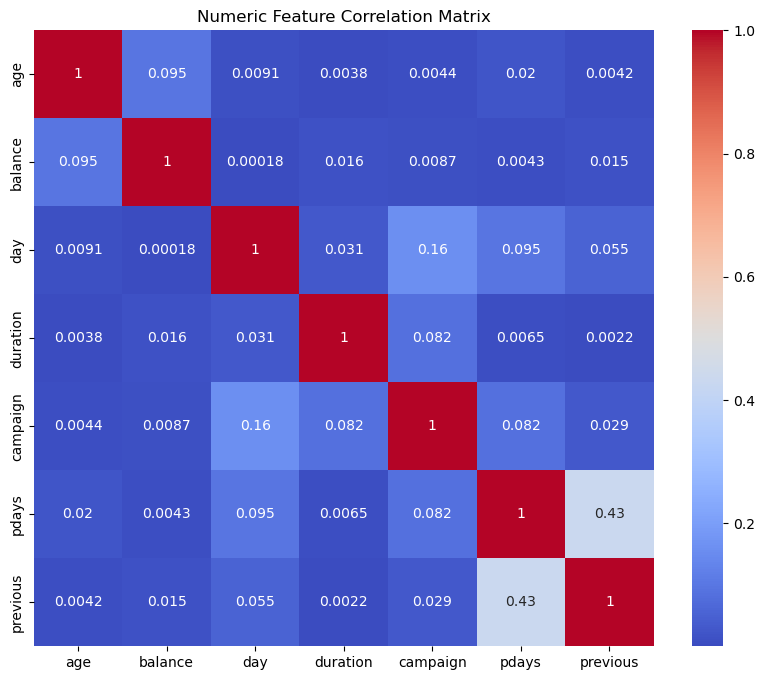

상관관계 0.9 이상 쌍: []


In [20]:
import seaborn as sns

# 상관관계 행렬
corr_matrix = X[num_cols].corr().abs()

# 히트맵 시각화
plt.figure(figsize=(10,8))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm')
plt.title("Numeric Feature Correlation Matrix")
plt.show()

# 상관계수 0.9 이상인 변수 쌍 찾기 (자기 자신 제외)
high_corr = [(col1, col2, corr_matrix.loc[col1, col2])
             for col1 in num_cols
             for col2 in num_cols
             if col1 != col2 and corr_matrix.loc[col1, col2] > 0.9]

print("상관관계 0.9 이상 쌍:", high_corr)


In [22]:
month_map = {'jan':1, 'feb':2, 'mar':3, 'apr':4, 'may':5, 'jun':6,
             'jul':7, 'aug':8, 'sep':9, 'oct':10, 'nov':11, 'dec':12}
X['month_num'] = X['month'].map(month_map)
X_test['month_num'] = X_test['month'].map(month_map)

# 기준 여름방학(5, 6, 7, 8월) / 겨울방학(12, 1월)
X['is_summer_vacation'] = X['month_num'].isin([6,7,8,9]).astype(int)
X['is_winter_vacation'] = X['month_num'].isin([12,1]).astype(int)

X_test['is_summer_vacation'] = X_test['month_num'].isin([5,6,7,8]).astype(int)
X_test['is_winter_vacation'] = X_test['month_num'].isin([12,1]).astype(int)

# 방학 전체로 합치려면
X['is_vacation'] = X['month_num'].isin([6,7,8,12,1]).astype(int)
X_test['is_vacation'] = X_test['month_num'].isin([6,7,8,12,1]).astype(int)


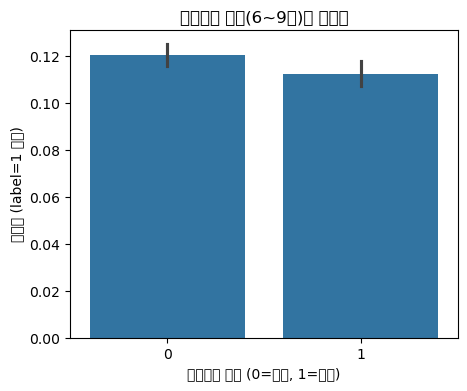

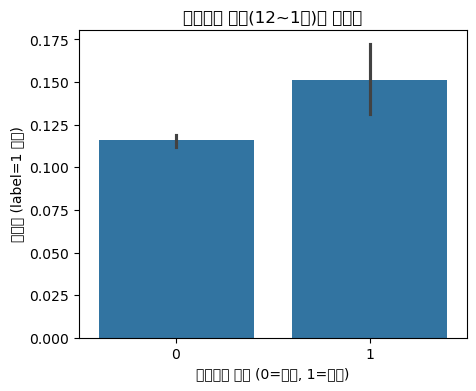

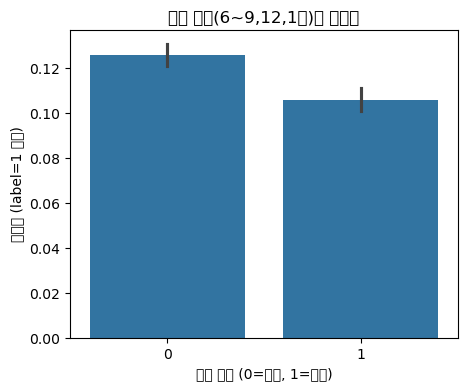

In [23]:
import matplotlib.pyplot as plt
import seaborn as sns

# is_summer_vacation_eu 기준
plt.figure(figsize=(5,4))
sns.barplot(x='is_summer_vacation', y='label', data=pd.concat([X, y], axis=1))
plt.title("여름방학 기간(6~9월)별 가입률")
plt.xlabel("여름방학 여부 (0=아님, 1=방학)")
plt.ylabel("가입률 (label=1 비율)")
plt.show()

# is_winter_vacation_eu 기준
plt.figure(figsize=(5,4))
sns.barplot(x='is_winter_vacation', y='label', data=pd.concat([X, y], axis=1))
plt.title("겨울방학 기간(12~1월)별 가입률")
plt.xlabel("겨울방학 여부 (0=아님, 1=방학)")
plt.ylabel("가입률 (label=1 비율)")
plt.show()

# is_vacation_eu 기준
plt.figure(figsize=(5,4))
sns.barplot(x='is_vacation', y='label', data=pd.concat([X, y], axis=1))
plt.title("방학 기간(6~9,12,1월)별 가입률")
plt.xlabel("방학 여부 (0=아님, 1=방학)")
plt.ylabel("가입률 (label=1 비율)")
plt.show()


In [24]:
X_enc = pd.get_dummies(X, drop_first=False)
print(X_enc.columns)

Index(['age', 'balance', 'day', 'duration', 'campaign', 'pdays', 'previous',
       'is_single', 'is_education_tertiary', 'is_retired',
       ...
       'job_education_unknown_unknown', 'age_bin_18-25', 'age_bin_26-35',
       'age_bin_36-45', 'age_bin_46-60', 'age_bin_60+', 'season_fall',
       'season_spring', 'season_summer', 'season_winter'],
      dtype='object', length=31765)


In [25]:
# month 변수는 이미 인코딩되어 있을 수도 있고, 아니면 문자 그대로일 수도 있음

# 문자 그대로 month가 있다면:
def make_season_features(df):
    # 문자 -> 숫자 mapping
    month_map = {'jan':1, 'feb':2, 'mar':3, 'apr':4, 'may':5, 'jun':6,
                 'jul':7, 'aug':8, 'sep':9, 'oct':10, 'nov':11, 'dec':12}
    df['month_num'] = df['month'].map(month_map)

    # 유럽 방학 시즌(6~9월)
    df['is_summer'] = df['month_num'].isin([6,7,8,9]).astype(int)
    # 겨울 휴일 시즌(12, 1월)
    df['is_winter'] = df['month_num'].isin([12,1]).astype(int)
    # 미국식 방학(5~8월)
    df['is_holiday'] = df['month_num'].isin([5,6,7,8]).astype(int)

    return df

# 사용 예시
X = make_season_features(X)


In [27]:
from sklearn.ensemble import RandomForestClassifier
import matplotlib.pyplot as plt

# 1. 실제 존재하는 컬럼만 사용
feature_list = season + other_features
actual_features = [col for col in feature_list if col in X_base.columns]

X_season = X_base[actual_features]

# 2. 모델 학습
rf = RandomForestClassifier(random_state=42)
rf.fit(X_season, y)

# 3. Feature importance 시각화 (상위 20개)
importances = rf.feature_importances_
indices = importances.argsort()[::-1][:20]  # 중요도 상위 20개

plt.figure(figsize=(8, 4))
plt.barh([actual_features[i] for i in indices], importances[indices])
plt.gca().invert_yaxis()
plt.title('Top 20 Feature Importances (RandomForest)')
plt.show()



NameError: name 'other_features' is not defined

In [ ]:
from sklearn.model_selection import train_test_split
from lightgbm import LGBMClassifier
from sklearn.metrics import f1_score, roc_auc_score
import json
from lightgbm import LGBMClassifier

# 데이터 분할
X_train, X_val, y_train, y_val = train_test_split(X_enc, y, test_size=0.2, stratify=y, random_state=42)

# best_params.json에서 파라미터 로드
with open("best_params.json", "r") as f:
    best_params = json.load(f)

# random_state, n_jobs 등 추가 (필요시)
model = LGBMClassifier(**best_params, random_state=42)

lgbm_params = {k.replace('model__', ''): v for k, v in best_params.items()}

from lightgbm import LGBMClassifier
model = LGBMClassifier(**lgbm_params)
model.fit(X_train, y_train)

# 예측 및 평가
y_pred = model.predict(X_val)
y_pred_proba = model.predict_proba(X_val)[:, 1]

f1 = f1_score(y_val, y_pred)
roc = roc_auc_score(y_val, y_pred_proba)
print(f"F1-score: {f1:.4f} | ROC-AUC: {roc:.4f}")


[LightGBM] [Info] Number of positive: 2962, number of negative: 22355
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.002345 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 1167
[LightGBM] [Info] Number of data points in the train set: 25317, number of used features: 116
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.116996 -> initscore=-2.021185
[LightGBM] [Info] Start training from score -2.021185
F1-score: 0.5637 | ROC-AUC: 0.9330


## threshold 찾기

Best threshold: 0.280 | Best F1-score: 0.6218


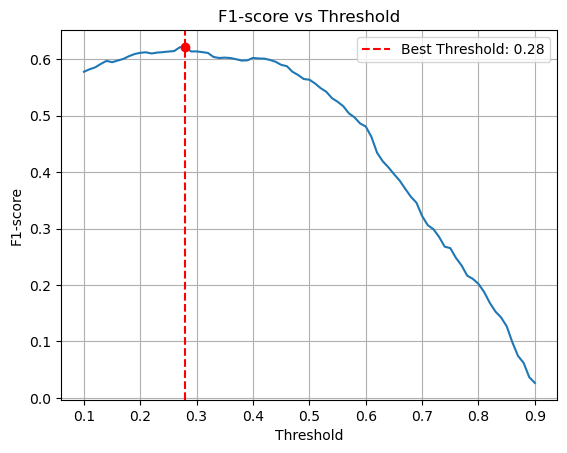

In [ ]:
import numpy as np
from sklearn.metrics import f1_score
import matplotlib.pyplot as plt

# 확률값 예측
probas = model.predict_proba(X_val)[:, 1]  # (X_valid = 검증셋 입력, y_valid = 정답)

# 여러 threshold에서 F1-score 계산
thresholds = np.linspace(0.1, 0.9, 81)
f1s = []
for thr in thresholds:
    preds = (probas > thr).astype(int)
    f1s.append(f1_score(y_valid, preds))

# 최적 threshold
best_thr = thresholds[np.argmax(f1s)]
best_f1 = np.max(f1s)
print(f'Best threshold: {best_thr:.3f} | Best F1-score: {best_f1:.4f}')

# 시각화
plt.plot(thresholds, f1s)
plt.xlabel('Threshold')
plt.ylabel('F1-score')
plt.title('F1-score vs Threshold')

plt.axvline(best_thr, color='red', linestyle='--', label=f'Best Threshold: {best_thr:.2f}')
plt.scatter([best_thr], [best_f1], color='red', zorder=5)
plt.legend()
plt.grid()
plt.show()

# 최적 threshold 적용 예측값
final_preds = (probas > best_thr).astype(int)


In [ ]:
# 이렇게 임계값을 낮게(0.5보다) 잡으면, 불균형 데이터에서 minority class(즉, label=1)의 recall을 더 높이고 전체 F1-score를 개선하는 효과가 있음.



              precision    recall  f1-score   support

           0       0.96      0.92      0.94      5590
           1       0.54      0.74      0.62       740

    accuracy                           0.90      6330
   macro avg       0.75      0.83      0.78      6330
weighted avg       0.91      0.90      0.90      6330



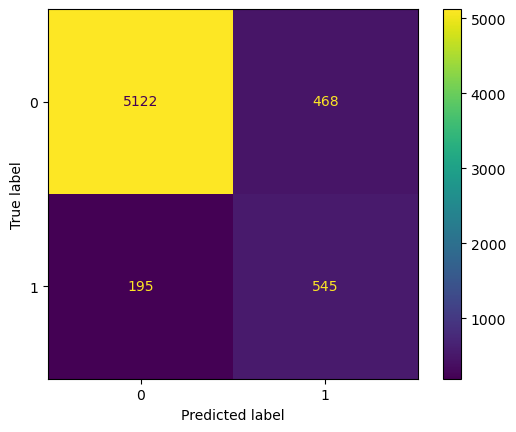

In [ ]:
from sklearn.metrics import confusion_matrix, classification_report, ConfusionMatrixDisplay

y_pred_thr = (y_pred_proba > best_thr).astype(int)
cm = confusion_matrix(y_val, y_pred_thr)
print(classification_report(y_val, y_pred_thr))
ConfusionMatrixDisplay(cm).plot()

In [ ]:
feature_imp = model.feature_importances_
sns.barplot(x=feature_imp, y=X_enc.columns)
plt.title("Feature Importances")
plt.show()

KeyboardInterrupt: 

In [ ]:
from imblearn.over_sampling import SMOTE

smote = SMOTE(random_state=42)
X_train_res, y_train_res = smote.fit_resample(X_train, y_train)
model.fit(X_train_res, y_train_res)


## PipeLine

#### 범주형 변수 pipeline 작성

- one hot encoder : binary 변수 일때 사용
    - 'default', 'loan', 'housing' (Y/N) , 'marital', 'contact' (유의미한 most_frequent에 해당하는 범주가 있음)
- target encder : 범주와 타겟간의 연관성이 명확할 때 사용
    - job, poutcome,
- ordinal encoder : 순서 있는 범주에 사용
    - education

In [ ]:
def binary(X):
    X = X.copy()
    for col in binary_cols:
        X[col] = X[col].map({'yes': 1, 'no': 0})
    return X

binary_transformer = FunctionTransformer(binary)

transformer = ColumnTransformer(
    transformers=[
        ('num', SimpleImputer(strategy='median'), num_cols),
        ('bin', binary_transformer, binary_cols),
        ('cat', OneHotEncoder(handle_unknown='ignore'), cat_cols)
    ]
)

In [ ]:
model_pipeline = Pipeline(steps=[
    ('preprocessor', transformer),
    ('model', LGBMClassifier(
        boosting_type='gbdt',         
        n_estimators=1000,
        learning_rate=0.05,
        num_leaves=64,
        subsample=0.5,
        colsample_bytree=1,
        random_state=42
    ))
])

In [ ]:
param_grid = {
    'model__boosting_type': ['gbdt', 'dart'],
    'model__n_estimators': [1000, 1500],
    'model__learning_rate': [0.01, 0.05, 0.1],
    'model__num_leaves': [64],
    'model__subsample': [0.5],
    'model__colsample_bytree': [1]
}

In [ ]:
cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)
grid = GridSearchCV(model_pipeline, param_grid, cv=cv, scoring='f1', n_jobs=-1, verbose=2)
grid.fit(X, y)

print("best 파라미터:", grid.best_params_)
print("best F1-score:", grid.best_score_)


Fitting 10 folds for each of 12 candidates, totalling 120 fits
[LightGBM] [Info] Number of positive: 3332, number of negative: 25150
[LightGBM] [Info] Number of positive: 3332, number of negative: 25150
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.008331 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 1021
[LightGBM] [Info] Number of data points in the train set: 28482, number of used features: 48
[LightGBM] [Info] Number of positive: 3332, number of negative: 25150
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.116986 -> initscore=-2.021285
[LightGBM] [Info] Start training from score -2.021285
[LightGBM] [Info] Number of positive: 3332, number of negative: 25150
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.003529 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if m

/opt/anaconda3/envs/pytorch/lib/python3.11/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


[CV] END model__boosting_type=gbdt, model__colsample_bytree=1, model__learning_rate=0.01, model__n_estimators=1000, model__num_leaves=64, model__subsample=0.5; total time= 1.4min


/opt/anaconda3/envs/pytorch/lib/python3.11/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


[CV] END model__boosting_type=gbdt, model__colsample_bytree=1, model__learning_rate=0.01, model__n_estimators=1000, model__num_leaves=64, model__subsample=0.5; total time= 1.4min
[LightGBM] [Info] Number of positive: 3332, number of negative: 25150
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.004808 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 1022
[LightGBM] [Info] Number of data points in the train set: 28482, number of used features: 48
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.116986 -> initscore=-2.021285
[LightGBM] [Info] Start training from score -2.021285


...

[CV] END model__boosting_type=dart, model__colsample_bytree=1, model__learning_rate=0.1, model__n_estimators=1500, model__num_leaves=64, model__subsample=0.5; total time= 3.2min


/opt/anaconda3/envs/pytorch/lib/python3.11/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


[CV] END model__boosting_type=dart, model__colsample_bytree=1, model__learning_rate=0.1, model__n_estimators=1500, model__num_leaves=64, model__subsample=0.5; total time= 3.0min


/opt/anaconda3/envs/pytorch/lib/python3.11/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


[CV] END model__boosting_type=dart, model__colsample_bytree=1, model__learning_rate=0.1, model__n_estimators=1500, model__num_leaves=64, model__subsample=0.5; total time= 2.7min
[LightGBM] [Info] Number of positive: 3702, number of negative: 27945
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.000955 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 1022
[LightGBM] [Info] Number of data points in the train set: 31647, number of used features: 48
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.116978 -> initscore=-2.021365
[LightGBM] [Info] Start training from score -2.021365
best 파라미터: {'model__boosting_type': 'gbdt', 'model__colsample_bytree': 1, 'model__learning_rate': 0.01, 'model__n_estimators': 1000, 'model__num_leaves': 64, 'model__subsample': 0.5}
best F1-score: 0.5466459321484027


In [ ]:
import json

# GridSearchCV를 돌린 뒤 (예: grid.fit(...))
best_params = grid.best_params_

# 저장 (예: best_params.json)
with open("best_params.json", "w") as f:
    json.dump(best_params, f)

In [ ]:
# 전체 train으로 재학습
best_model = grid.best_estimator_
best_model.fit(X, y)

# 테스트 데이터 예측
test_pred = best_model.predict(X_test)

[LightGBM] [Info] Number of positive: 3702, number of negative: 27945
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.000986 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 1022
[LightGBM] [Info] Number of data points in the train set: 31647, number of used features: 48
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.116978 -> initscore=-2.021365
[LightGBM] [Info] Start training from score -2.021365


## Submission

In [ ]:
submission = pd.read_csv("submission_example.csv")
submission['label'] = test_pred  # 실제 제출 양식에 맞게 컬럼명 변경
submission.to_csv('submission_try02.csv', index=False)